This notebook loads the cached intermediate results produced by
`compare_z_slice_number_segmentations.ipynb` (the IOU and volume tables saved as parquet
under `../processed_data/`) and re-plots them with R/ggplot2. It does not re-read any masks,
so it is fast to iterate on figure styling without re-running the (slow) Python comparison.

See `compare_z_slice_number_segmentations.ipynb` and `../README.md` for what the
`z_comparison` labels (e.g. `1um vs 0.5um`) mean and how the tables were computed.


In [1]:
list_of_packages <- c("ggplot2", "dplyr", "arrow", "ggsignif")
for (package in list_of_packages) {
    suppressPackageStartupMessages(
        suppressWarnings(
            library(
                package,
                character.only = TRUE,
                quietly = TRUE,
                warn.conflicts = FALSE
            )
        )
    )
}
git_root <- system("git rev-parse --show-toplevel", intern = TRUE)
plot_theme <- theme_bw() + theme(
        axis.text = element_text(size = 14),
        axis.text.x = element_text(angle = 45, hjust = 1),
        axis.title = element_text(size = 16),
        legend.text = element_text(size = 14),
        legend.title = element_text(size = 16),
        strip.text = element_text(size = 14),
        plot.title = element_text(size = 18, hjust = 0.5)
    )

figures_path <- file.path(git_root, "5.technical_analysis/figures/zslice_segmentation_comparison")
if (!dir.exists(figures_path)) {
  dir.create(figures_path, recursive = TRUE)
}

processed_data_dir <- file.path(git_root, "5.technical_analysis/processed_data")
iou_results_path <- file.path(processed_data_dir, "zslice_iou_results.parquet")
per_compartment_volume_path <- file.path(processed_data_dir, "zslice_per_compartment_volume.parquet")


In [2]:
iou_results_df <- as.data.frame(arrow::read_parquet(iou_results_path))
per_compartment_volume_df <- as.data.frame(arrow::read_parquet(per_compartment_volume_path))

head(iou_results_df)
head(per_compartment_volume_df)


,patient,well_fov,z_comparison,IOU,compartment,volume_ratio
,<chr>,<chr>,<chr>,<dbl>,<ord>,<dbl>
1,NF0037,F4-2,1um vs 0.5um,0.7997007,nuclei,0.6395636
2,NF0037,F4-2,1um vs 0.2um,0.7394399,nuclei,0.3451984
3,NF0037,F4-2,1um vs 0.1um,0.7252664,nuclei,0.1899833
4,NF0037,F4-2,0.5um vs 0.2um,0.8500453,nuclei,0.5397405
5,NF0037,F4-2,0.5um vs 0.1um,0.8298490,nuclei,0.2970515
6,NF0037,F4-2,0.2um vs 0.1um,0.9164314,nuclei,0.5503598


,patient,well_fov,z_slice_step,compartment,volume,normalized_volume
,<chr>,<chr>,<chr>,<chr>,<int>,<dbl>
1,NF0037,F4-2,1um,nuclei,1527993,1.0000000
2,NF0037,F4-2,0.5um,nuclei,1365942,0.8818912
3,NF0037,F4-2,0.2um,nuclei,1317421,0.8465272
4,NF0037,F4-2,0.1um,nuclei,1279564,0.8189356
5,NF0037,F4-2,1um,cell,14639931,1.0000000
6,NF0037,F4-2,0.5um,cell,13665104,0.9260592


In [3]:
# match the compartment ordering used in the Python notebook
compartment_levels <- c("organoid", "nuclei", "cytoplasm", "cell")
iou_results_df$compartment <- factor(iou_results_df$compartment, levels = compartment_levels)
per_compartment_volume_df$compartment <- factor(
    per_compartment_volume_df$compartment, levels = compartment_levels
)

# fixed, colorblind-friendly (Okabe-Ito) qualitative palette for compartment --
# these are unordered categories, so a perceptual/sequential palette like viridis
# isn't the right tool here
compartment_palette <- c(
    "organoid" = "#E69F00",
    "nuclei" = "#56B4E9",
    "cytoplasm" = "#009E73",
    "cell" = "#CC79A7"
)

# treat 0.1um (the finest step tested) as the reference, and only keep the 3
# z-step comparisons that compare a coarser step against it -- drop the 3
# coarser-vs-coarser comparisons (e.g. 1um vs 0.5um), which aren't of interest here
z_comparison_levels <- c("1um vs 0.1um", "0.5um vs 0.1um", "0.2um vs 0.1um")
iou_results_df <- iou_results_df %>% filter(z_comparison %in% z_comparison_levels)
iou_results_df$z_comparison <- factor(iou_results_df$z_comparison, levels = z_comparison_levels)

# every pairwise combination among the remaining 3 comparisons, for the
# significance brackets below
z_comparison_pairs <- combn(z_comparison_levels, 2, simplify = FALSE)

# qualitative (ColorBrewer "Dark2") palette for the 3 remaining z-step comparisons
z_comparison_palette <- c(
    "1um vs 0.1um" = "#1B9E77",
    "0.5um vs 0.1um" = "#D95F02",
    "0.2um vs 0.1um" = "#7570B3"
)

z_slice_step_levels <- c("1um", "0.5um", "0.2um", "0.1um")
per_compartment_volume_df$z_slice_step <- factor(
    per_compartment_volume_df$z_slice_step, levels = z_slice_step_levels
)

# again treat 0.1um as the reference step: only compare each coarser step against
# 0.1um, not against each other
z_slice_step_pairs <- lapply(
    setdiff(z_slice_step_levels, "0.1um"), function(step) c(step, "0.1um")
)

head(iou_results_df)
head(per_compartment_volume_df)


,patient,well_fov,z_comparison,IOU,compartment,volume_ratio
,<chr>,<chr>,<fct>,<dbl>,<ord>,<dbl>
1,NF0037,F4-2,1um vs 0.1um,0.7252664,nuclei,0.1899833
2,NF0037,F4-2,0.5um vs 0.1um,0.8298490,nuclei,0.2970515
3,NF0037,F4-2,0.2um vs 0.1um,0.9164314,nuclei,0.5503598
4,NF0037,F4-2,1um vs 0.1um,0.8898997,cell,0.1776592
5,NF0037,F4-2,0.5um vs 0.1um,0.9350328,cell,0.2930111
6,NF0037,F4-2,0.2um vs 0.1um,0.9602239,cell,0.5266155


,patient,well_fov,z_slice_step,compartment,volume,normalized_volume
,<chr>,<chr>,<fct>,<fct>,<int>,<dbl>
1,NF0037,F4-2,1um,nuclei,1527993,1.0000000
2,NF0037,F4-2,0.5um,nuclei,1365942,0.8818912
3,NF0037,F4-2,0.2um,nuclei,1317421,0.8465272
4,NF0037,F4-2,0.1um,nuclei,1279564,0.8189356
5,NF0037,F4-2,1um,cell,14639931,1.0000000
6,NF0037,F4-2,0.5um,cell,13665104,0.9260592


Warning message in wilcox.test.default(c(0.601816056819193, 0.669252477787665, 0.69381489910599, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.601816056819193, 0.669252477787665, 0.69381489910599, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.745848915207651, 0.800851470096049, 0.845019739492677, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.601816056819193, 0.669252477787665, 0.69381489910599, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.601816056819193, 0.669252477787665, 0.69381489910599, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.745848915207651, 0.800851470096049, 0.845019739492677, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.719443160579796, 0.737845757515782, 0.521083652635151, :
“cannot compute exact p-value with ties”
Warning message i

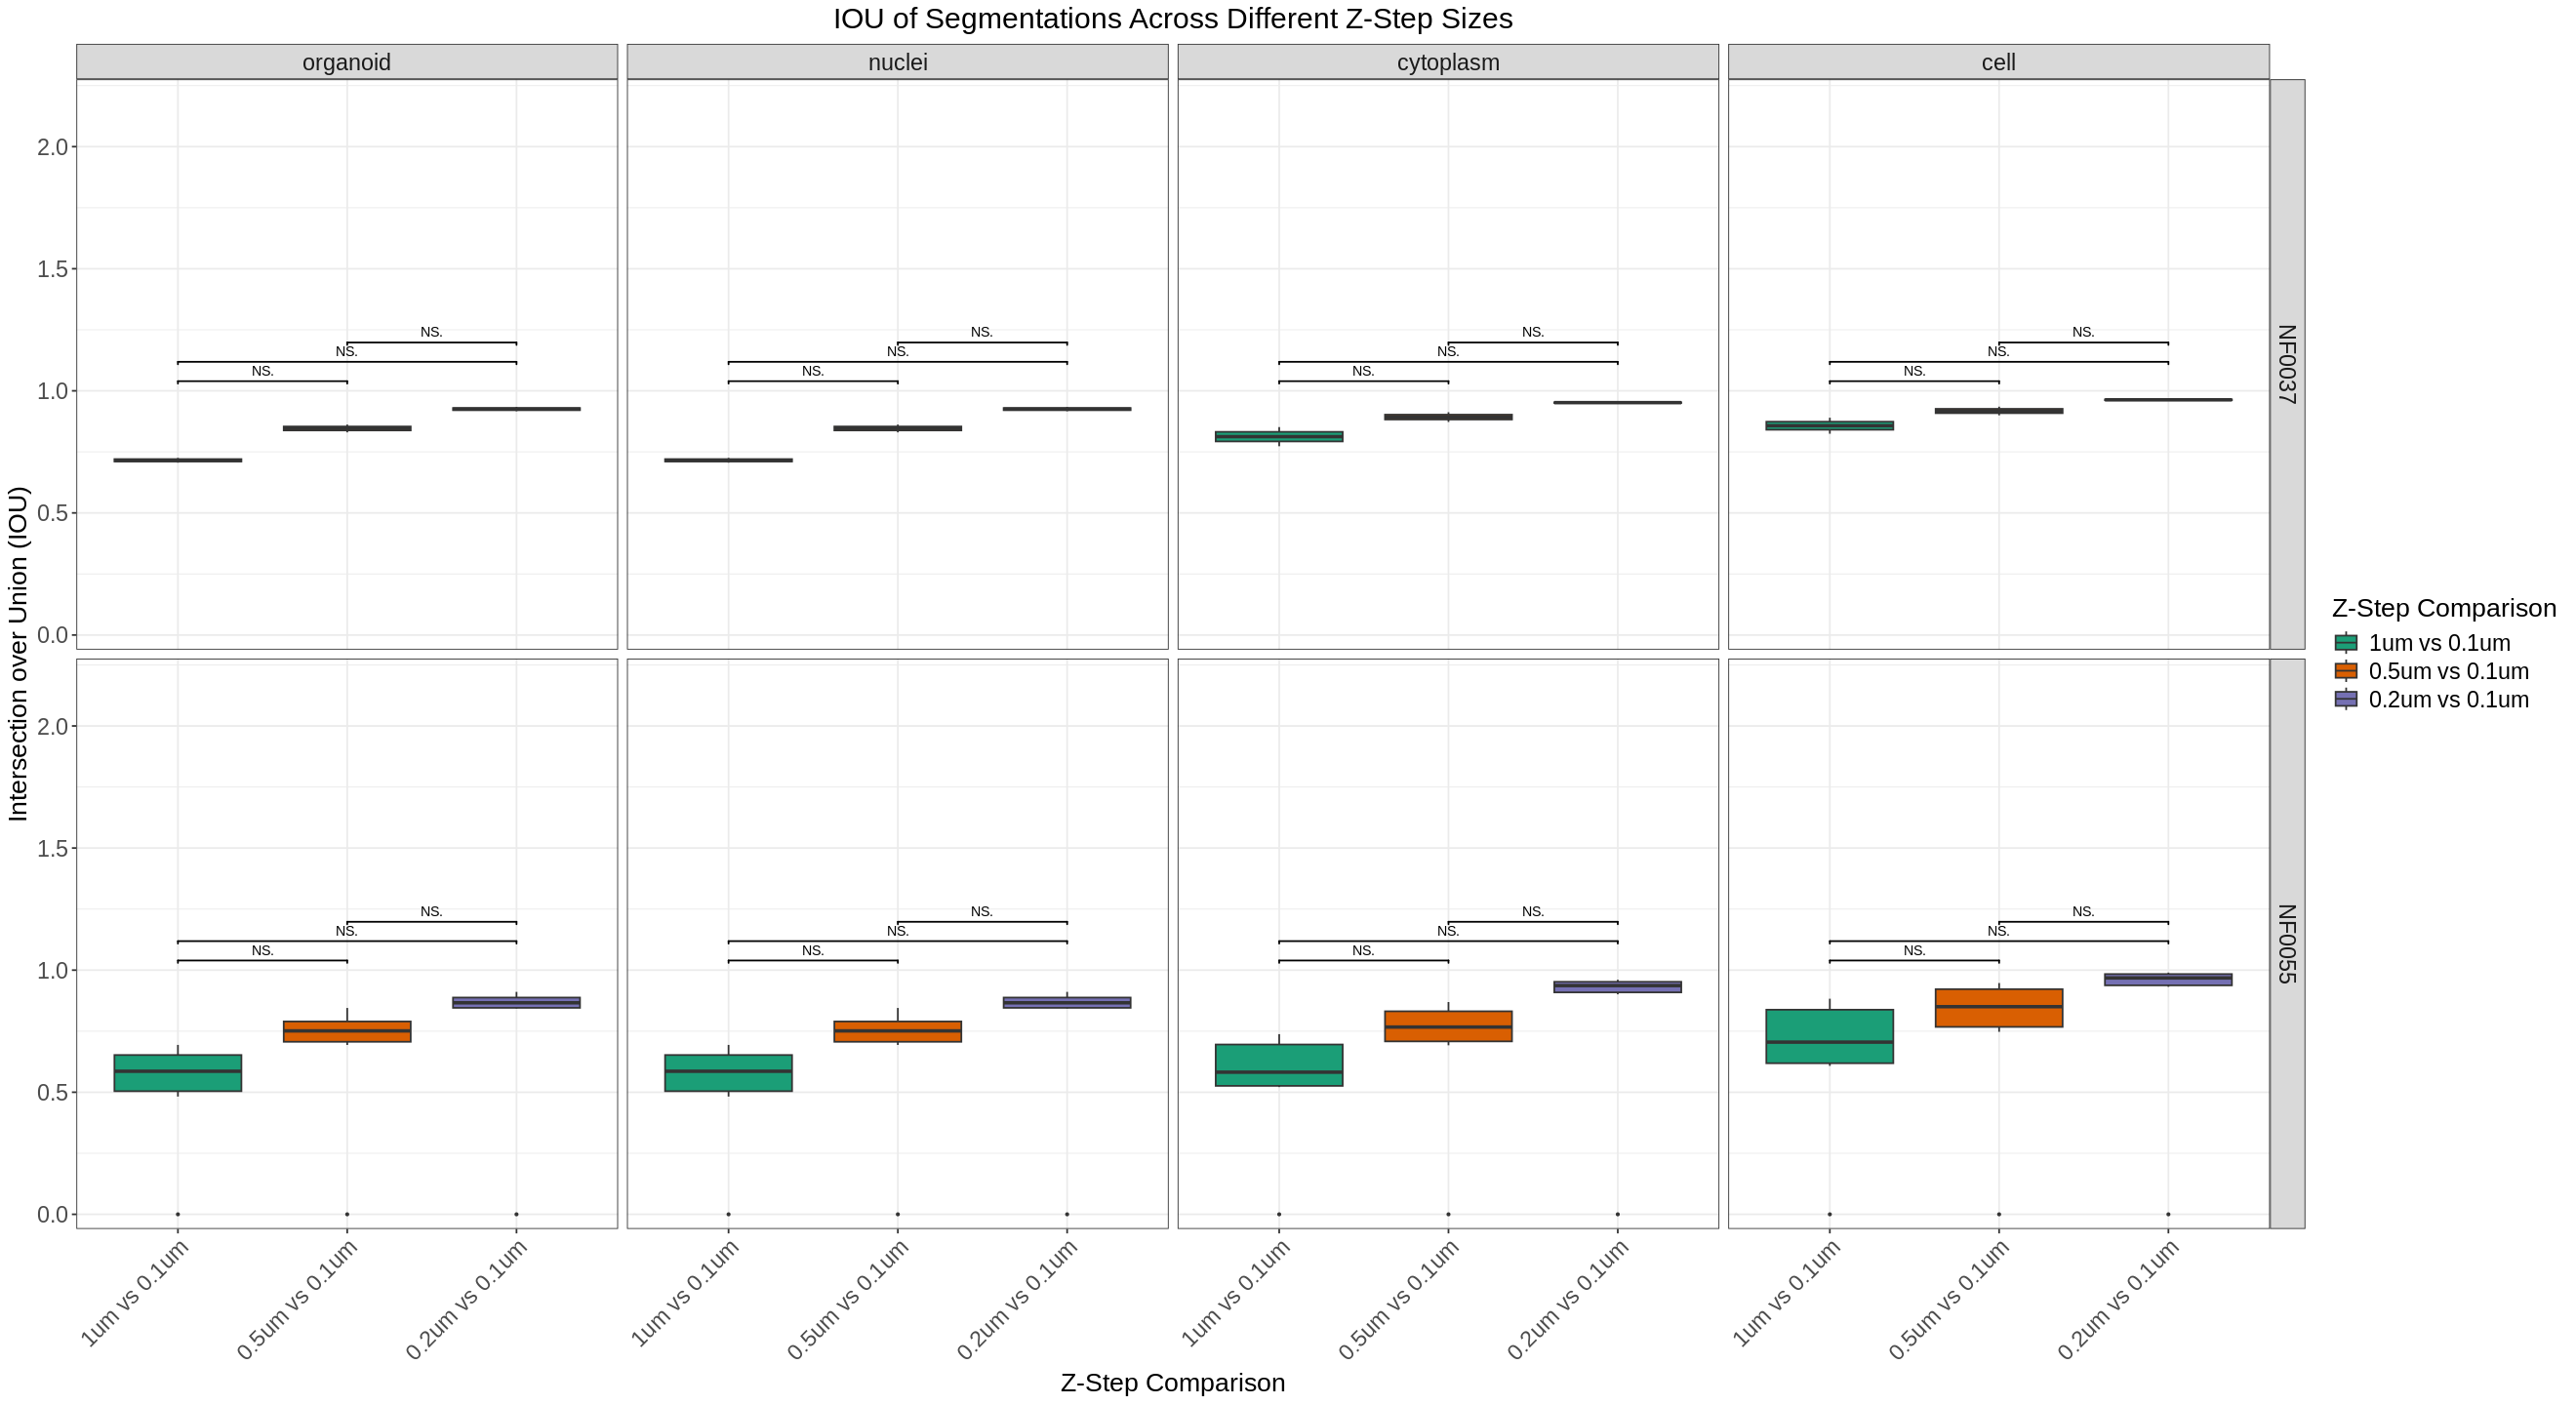

In [4]:
width <- 18
height <- 10
options(repr.plot.width = width, repr.plot.height = height)

# one boxplot per z-step comparison (not dodged), faceted by compartment x patient, so
# pairwise significance brackets have unambiguous x-positions to anchor to.
# 0.1um (the finest step tested) is treated as the reference, so only the 3
# comparisons against it are kept (see z_comparison_levels above); all 3 pairwise
# combinations among those are tested (Wilcoxon rank-sum, computed per facet by
# geom_signif itself) and labeled ns / * / ** / *** -- not just the significant ones --
# so absence of a difference is visible too, not only presence of one.
iou_plot <- (
    ggplot(
        data = iou_results_df,
        aes(x = z_comparison, y = IOU, fill = z_comparison)
    )
    + geom_boxplot(outlier.size = 0.5)
    + geom_signif(
        comparisons = z_comparison_pairs,
        test = "wilcox.test",
        map_signif_level = TRUE,
        step_increase = 0.08,
        tip_length = 0.01,
        textsize = 3
    )
    + scale_fill_manual(values = z_comparison_palette)
    + facet_grid(rows = vars(patient), cols = vars(compartment))
    + scale_y_continuous(limits = c(0, NA), expand = expansion(mult = c(0.05, 0.4)))
    + labs(
        x = "Z-Step Comparison (vs. 0.1um reference)",
        y = "Intersection over Union (IOU)",
        title = "IOU of Segmentations: Each Z-Step Size vs. the 0.1um Reference",
        fill = "Z-Step Comparison"
    )
    + plot_theme
)
ggsave(
    filename = file.path(figures_path, "iou_by_zstep_comparison.png"),
    plot = iou_plot,
    width = width,
    height = height,
    units = "in",
    dpi = 600
)
iou_plot


Warning message in wilcox.test.default(c(0.17708405875687, 0.220034339815182, 0.122027399104924, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.17708405875687, 0.220034339815182, 0.122027399104924, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.3538242999829, 0.323811948884119, 0.255960152905755, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.17708405875687, 0.220034339815182, 0.122027399104924, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.17708405875687, 0.220034339815182, 0.122027399104924, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.3538242999829, 0.323811948884119, 0.255960152905755, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.167491420337472, 0.192955715359201, 0.250758042782033, :
“cannot compute exact p-value with ties”
Warning message in wi

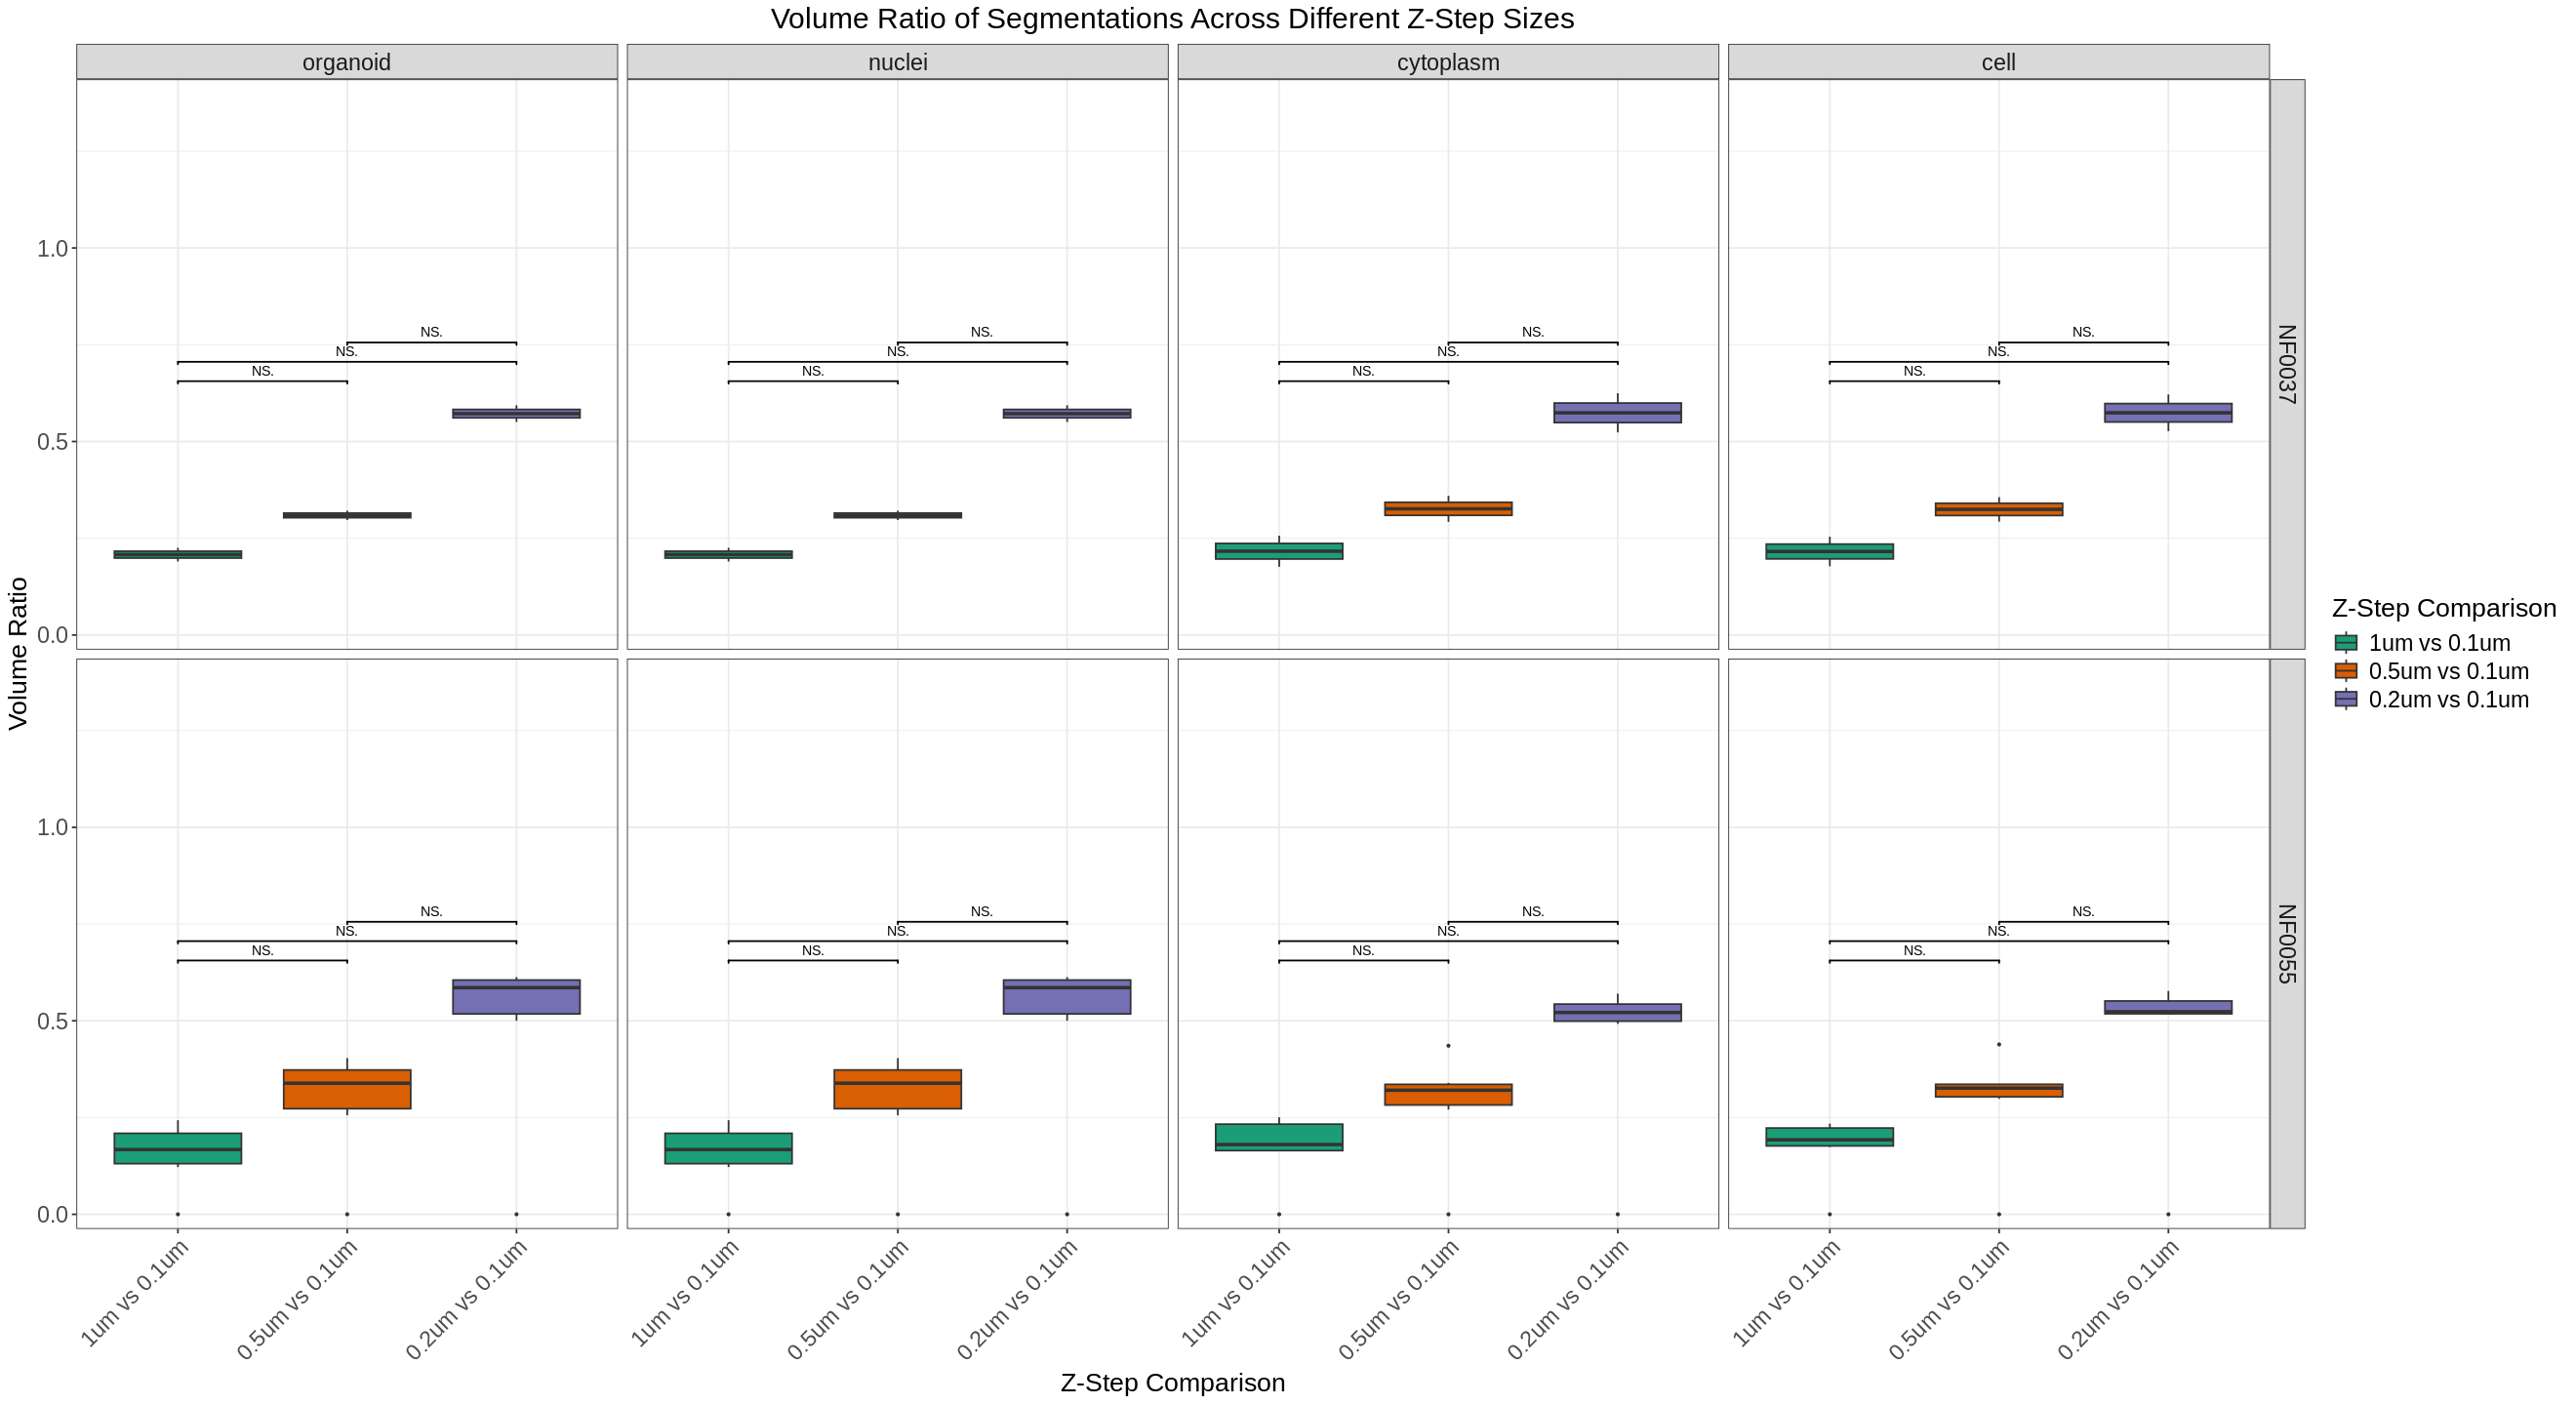

In [5]:
# same restructuring as iou_plot: one box per z-step comparison (vs. the 0.1um
# reference), faceted by compartment x patient, with the 3 pairwise Wilcoxon
# comparisons among them annotated
volume_ratio_plot <- (
    ggplot(
        data = iou_results_df,
        aes(x = z_comparison, y = volume_ratio, fill = z_comparison)
    )
    + geom_boxplot(outlier.size = 0.5)
    + geom_signif(
        comparisons = z_comparison_pairs,
        test = "wilcox.test",
        map_signif_level = TRUE,
        step_increase = 0.08,
        tip_length = 0.01,
        textsize = 3
    )
    + scale_fill_manual(values = z_comparison_palette)
    + facet_grid(rows = vars(patient), cols = vars(compartment))
    + scale_y_continuous(expand = expansion(mult = c(0.05, 0.4)))
    + labs(
        x = "Z-Step Comparison (vs. 0.1um reference)",
        y = "Volume Ratio",
        title = "Volume Ratio: Each Z-Step Size vs. the 0.1um Reference",
        fill = "Z-Step Comparison"
    )
    + plot_theme
)
ggsave(
    filename = file.path(figures_path, "volume_ratio_by_zstep_comparison.png"),
    plot = volume_ratio_plot,
    width = width,
    height = height,
    units = "in",
    dpi = 600
)
volume_ratio_plot


In [6]:
# the Python notebook saves the normalized table directly (so both notebooks agree on
# the normalization); load it if present, otherwise compute + persist it here
per_compartment_volume_normalized_path <- file.path(
    processed_data_dir, "zslice_per_compartment_volume_normalized.parquet"
)
if (file.exists(per_compartment_volume_normalized_path)) {
    per_compartment_volume_df <- as.data.frame(
        arrow::read_parquet(per_compartment_volume_normalized_path)
    )
    per_compartment_volume_df$compartment <- factor(
        per_compartment_volume_df$compartment, levels = compartment_levels
    )
    per_compartment_volume_df$z_slice_step <- factor(
        per_compartment_volume_df$z_slice_step, levels = z_slice_step_levels
    )
} else {
    # min-max normalize per patient + compartment (same definition as the Python
    # notebook), since absolute volume scale differs across patients
    per_compartment_volume_df <- per_compartment_volume_df %>%
        group_by(patient, compartment) %>%
        mutate(
            normalized_volume = (volume - min(volume)) / (max(volume) - min(volume))
        ) %>%
        ungroup()
    arrow::write_parquet(per_compartment_volume_df, per_compartment_volume_normalized_path)
}


Warning message in wilcox.test.default(c(0.261693441299763, 0.214109407139324, 0.88102064727784, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.255645064701747, 0.189327987085688, 0.945911422396959, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.244080506157732, 0.183284297133335, 1, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.261693441299763, 0.214109407139324, 0.88102064727784, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.255645064701747, 0.189327987085688, 0.945911422396959, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.244080506157732, 0.183284297133335, 1, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.351395851770946, 0.273910615245949, 1, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.327461998879853, 0.2

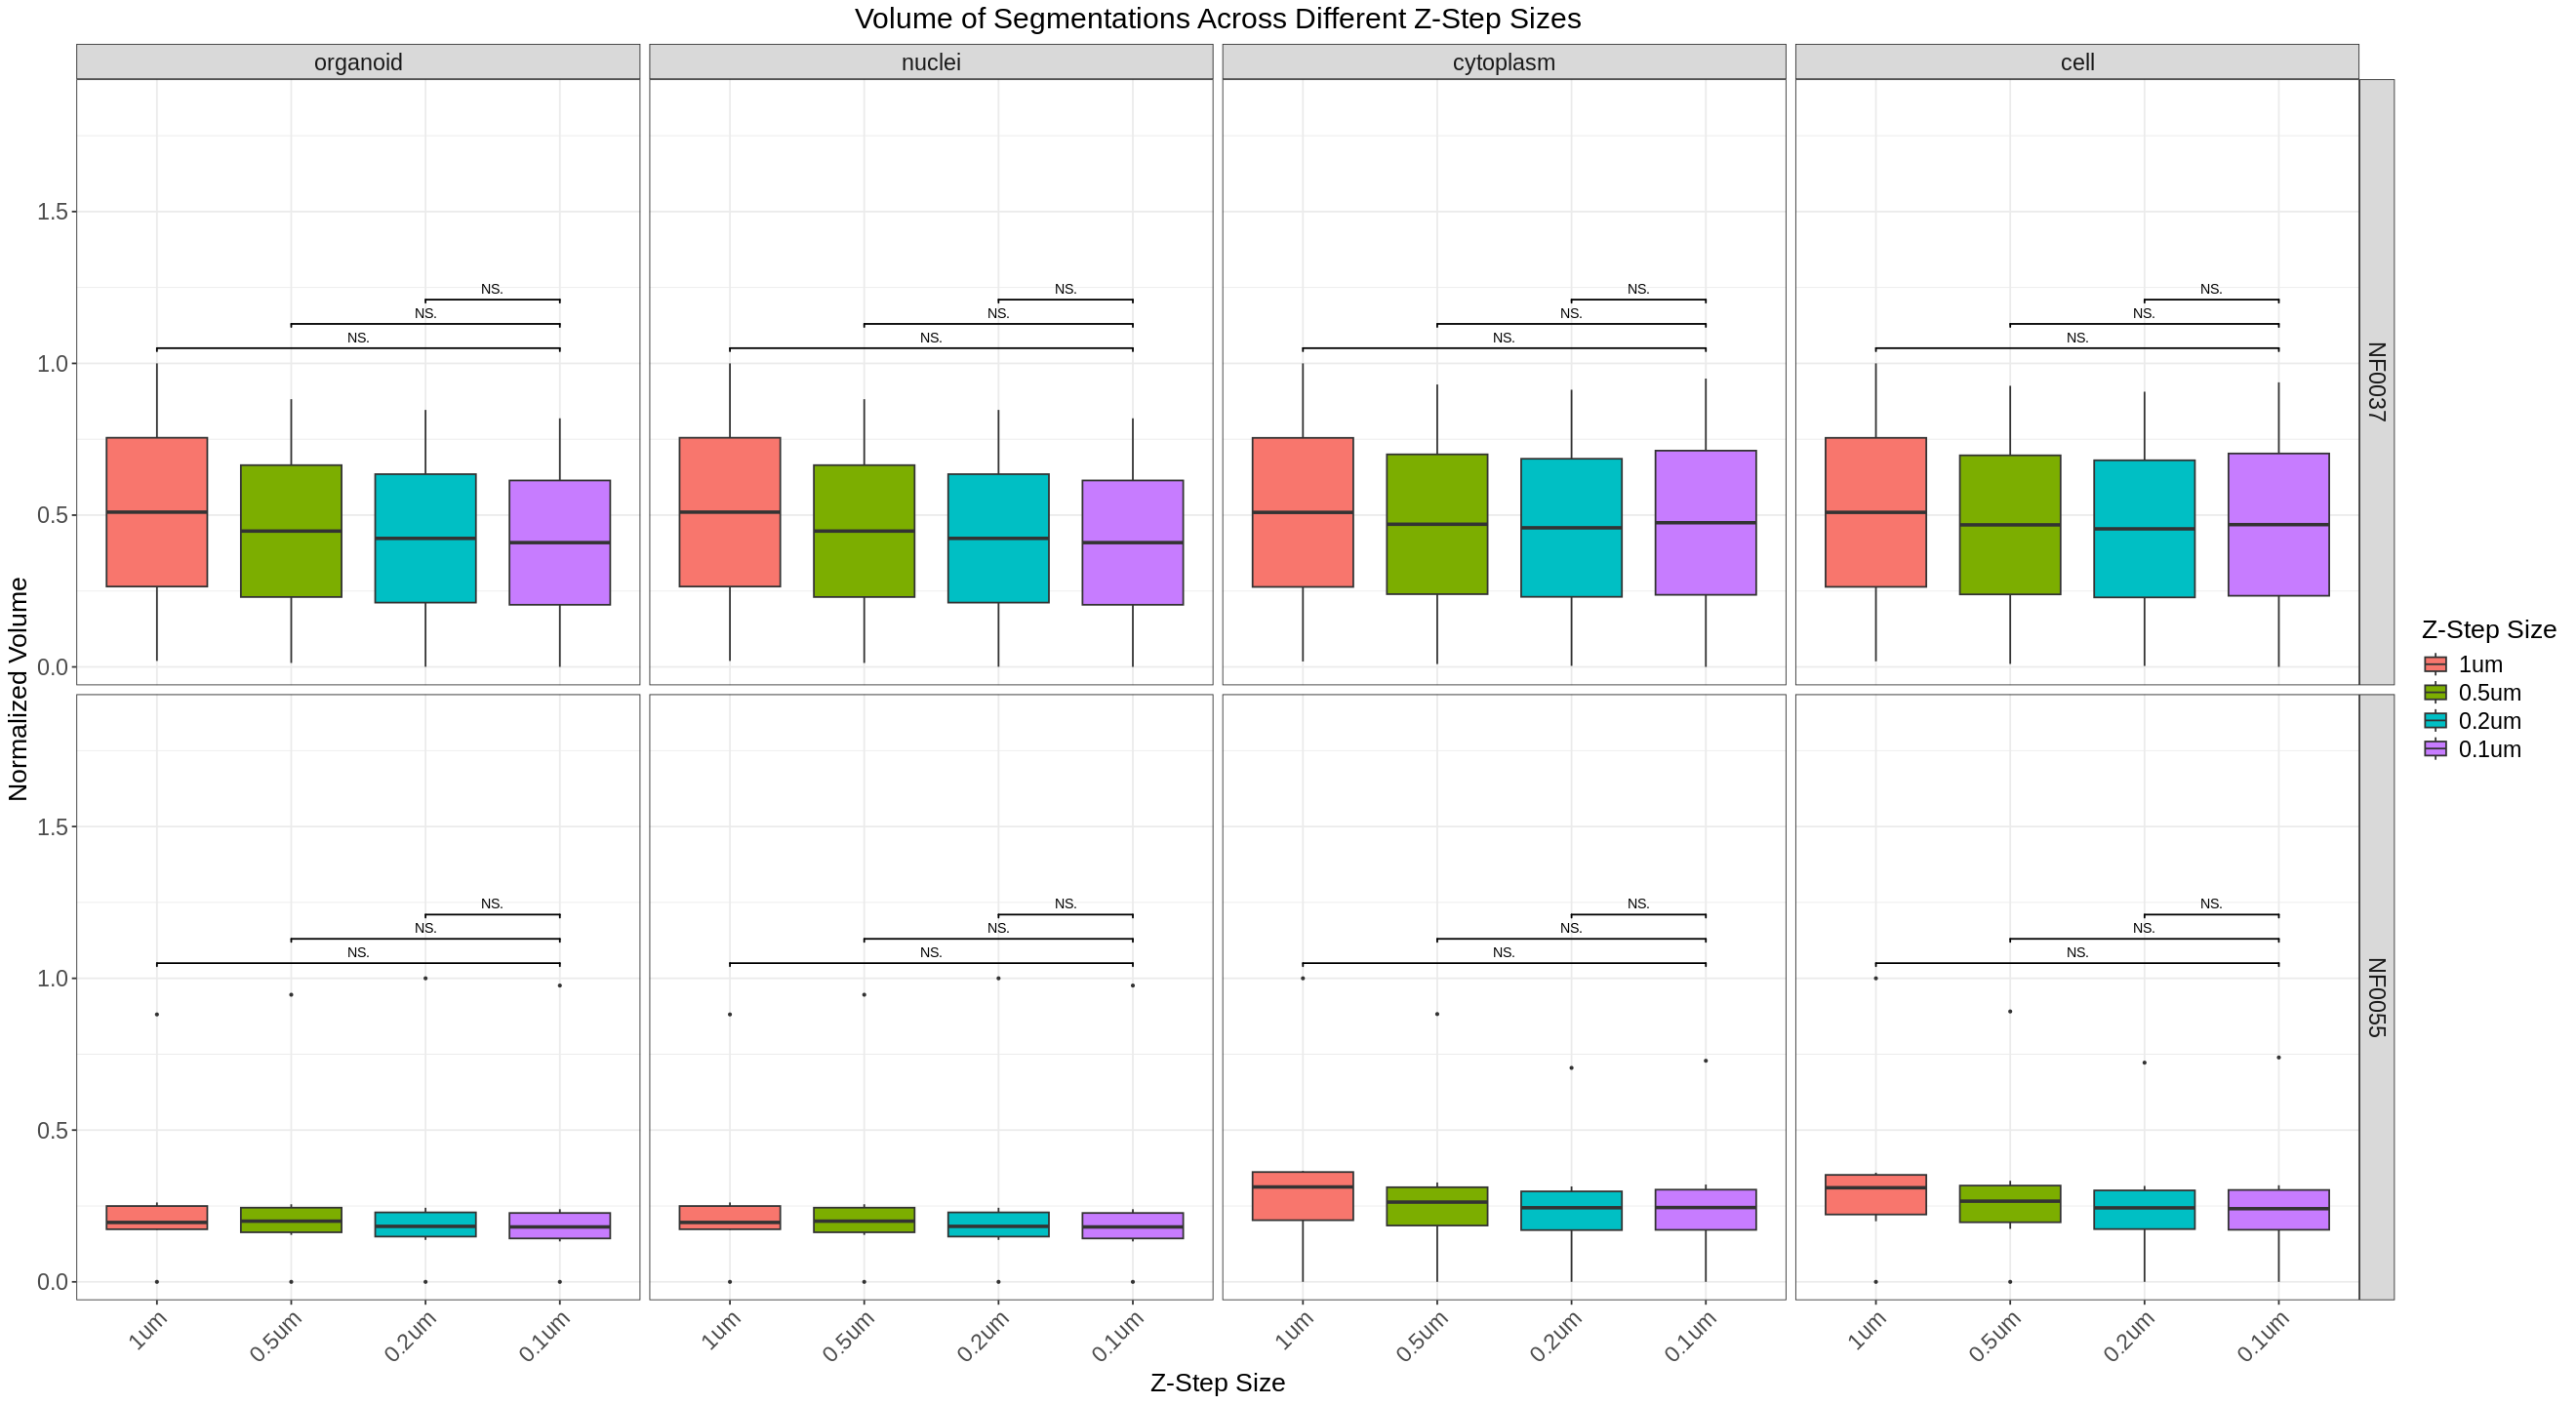

In [7]:
# same restructuring as iou_plot/volume_ratio_plot: one box per z-slice-step,
# faceted by compartment x patient; 0.1um is the reference step, so only the 3
# pairwise Wilcoxon comparisons against it are annotated (see z_slice_step_pairs above)
normalized_volume_plot <- (
    ggplot(
        data = per_compartment_volume_df,
        aes(x = z_slice_step, y = normalized_volume, fill = z_slice_step)
    )
    + geom_boxplot(outlier.size = 0.5)
    + geom_signif(
        comparisons = z_slice_step_pairs,
        test = "wilcox.test",
        map_signif_level = TRUE,
        step_increase = 0.08,
        tip_length = 0.01,
        textsize = 3
    )
    + facet_grid(rows = vars(patient), cols = vars(compartment))
    + scale_y_continuous(expand = expansion(mult = c(0.05, 0.4)))
    + labs(
        x = "Z-Step Size (vs. 0.1um reference)",
        y = "Normalized Volume",
        title = "Volume of Segmentations: Each Z-Step Size vs. the 0.1um Reference",
        fill = "Z-Step Size"
    )
    + plot_theme
)
ggsave(
    filename = file.path(figures_path, "normalized_volume_by_zstep.png"),
    plot = normalized_volume_plot,
    width = width,
    height = height,
    units = "in",
    dpi = 600
)
normalized_volume_plot
